In [1]:
import pandas as pd
import numpy as np

data_path = "../data/raw/creditcard.csv"

df_fraud = pd.read_csv(data_path)

print("Dataset shape:", df_fraud.shape)

Dataset shape: (284807, 31)


In [2]:
df_fraud.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df_fraud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
print("Missing values:")
print(df_fraud.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_fraud.duplicated().sum())

Missing values:
0

Duplicate rows:
1081


In [5]:
print(df_fraud["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [6]:
print(df_fraud["Class"].value_counts(normalize=True) * 100)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [7]:
duplicate_rows = df_fraud[df_fraud.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicate_rows))

print("\nClass distribution among duplicate rows:")
print(duplicate_rows["Class"].value_counts())

print("\nClass proportions among duplicate rows:")
print(duplicate_rows["Class"].value_counts(normalize=True) * 100)

Total duplicate rows: 1854

Class distribution among duplicate rows:
Class
0    1822
1      32
Name: count, dtype: int64

Class proportions among duplicate rows:
Class
0    98.274002
1     1.725998
Name: proportion, dtype: float64


In [8]:
print(duplicate_rows.head(20))

        Time        V1        V2        V3        V4        V5        V6  \
32      26.0 -0.529912  0.873892  1.347247  0.145457  0.414209  0.100223   
33      26.0 -0.529912  0.873892  1.347247  0.145457  0.414209  0.100223   
34      26.0 -0.535388  0.865268  1.351076  0.147575  0.433680  0.086983   
35      26.0 -0.535388  0.865268  1.351076  0.147575  0.433680  0.086983   
112     74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
113     74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
114     74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
115     74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
220    145.0 -2.420413  1.947885  0.553646  0.983069 -0.281518  2.408958   
221    145.0 -2.420413  1.947885  0.553646  0.983069 -0.281518  2.408958   
222    145.0 -2.419486  1.949346  0.552998  0.982710 -0.284815  2.411200   
223    145.0 -2.419486  1.949346  0.552998  0.982710 -0.284815  2.411200   
1177   919.0

In [9]:
print("Unique duplicate groups:", duplicate_rows.drop_duplicates().shape[0])

Unique duplicate groups: 773


In [10]:
# Find duplicate transaction groups based on all features except the index
duplicate_groups = (
    df_fraud
    .groupby(
        [col for col in df_fraud.columns if col != "Class"],
        dropna=False
    )["Class"]
    .agg(["count", "nunique"])
    .reset_index()
)

print("Duplicate groups with mixed Class labels:")
print(
    duplicate_groups[duplicate_groups["nunique"] > 1]
)

Duplicate groups with mixed Class labels:
Empty DataFrame
Columns: [Time, V1, V2, V3, V4, V5, V6, V7, V8, V9, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Amount, count, nunique]
Index: []

[0 rows x 32 columns]


In [11]:
mixed_label_groups = duplicate_groups[
    duplicate_groups["nunique"] > 1
]

print("Number of mixed-label duplicate groups:",
      len(mixed_label_groups))

Number of mixed-label duplicate groups: 0


In [12]:
df_fraud_clean = df_fraud.drop_duplicates().copy()

print("Original shape:", df_fraud.shape)
print("After removing duplicates:", df_fraud_clean.shape)
print("Rows removed:", len(df_fraud) - len(df_fraud_clean))

Original shape: (284807, 31)
After removing duplicates: (283726, 31)
Rows removed: 1081


In [13]:
print(df_fraud_clean["Class"].value_counts())
print()
print(df_fraud_clean["Class"].value_counts(normalize=True) * 100)

Class
0    283253
1       473
Name: count, dtype: int64

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


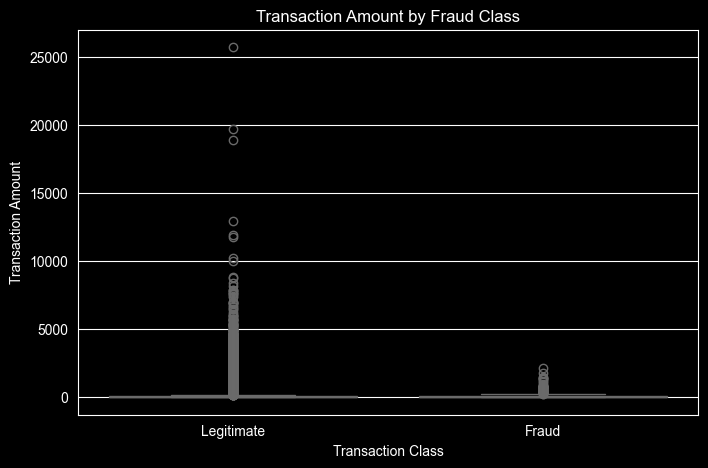

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_fraud_clean,
    x="Class",
    y="Amount"
)

plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount by Fraud Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [15]:
amount_summary = (
    df_fraud_clean
    .groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "min", "max"])
)

amount_summary

,count,mean,median,min,max
Class,,,,,
0,283253,88.413575,22.00,0.0,25691.16
1,473,123.871860,9.82,0.0,2125.87


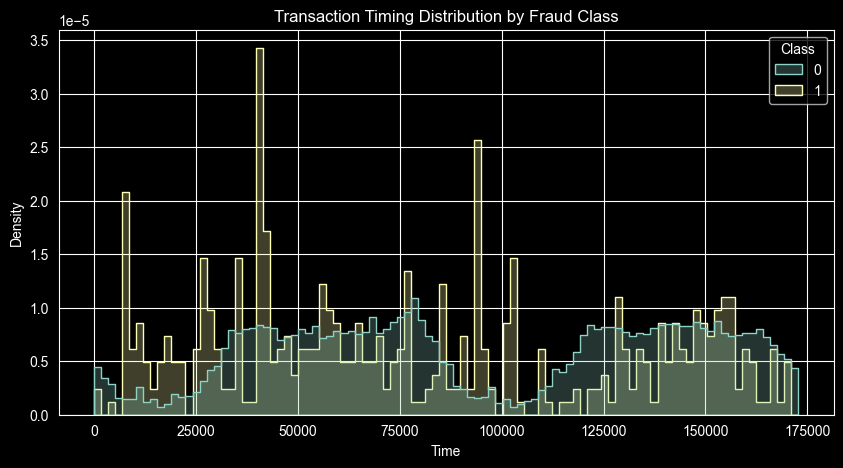

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_fraud_clean,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlabel("Time")
plt.ylabel("Density")
plt.title("Transaction Timing Distribution by Fraud Class")
plt.show()

In [17]:
v_features = [f"V{i}" for i in range(1, 29)]

feature_means = (
    df_fraud_clean
    .groupby("Class")[v_features]
    .mean()
    .T
)

feature_means.columns = ["Legitimate", "Fraud"]

feature_means["Absolute Difference"] = (
    feature_means["Fraud"] - feature_means["Legitimate"]
).abs()

feature_means.sort_values(
    "Absolute Difference",
    ascending=False
).head(10)

,Legitimate,Fraud,Absolute Difference
V14,0.011668,-6.835946,6.847614
V3,0.012853,-6.729599,6.742452
V17,0.010963,-6.463285,6.474249
V12,0.009476,-6.103254,6.112730
V10,0.007663,-5.453274,5.460937
V7,0.010447,-5.175912,5.186359
V1,0.013439,-4.498280,4.511719
V4,-0.010440,4.472591,4.483031
V16,0.007845,-4.000956,4.008801
V11,-0.006004,3.716347,3.722350


In [18]:
feature_correlations = (
    df_fraud_clean[v_features + ["Class"]]
    .corr()["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

feature_correlations.head(10)

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: Class, dtype: float64

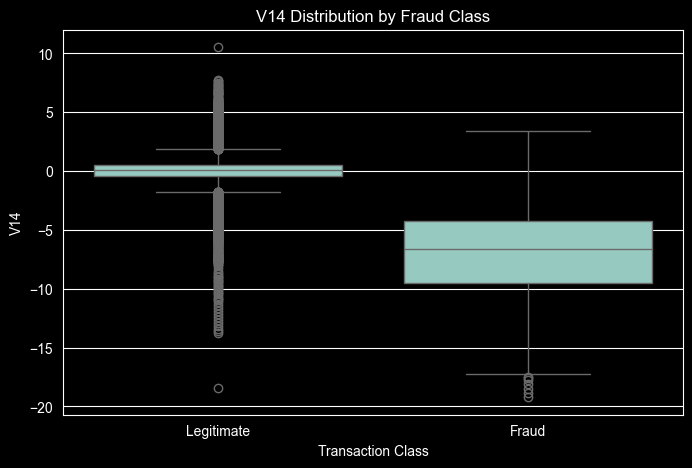

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_fraud_clean,
    x="Class",
    y="V14"
)

plt.xlabel("Transaction Class")
plt.ylabel("V14")
plt.title("V14 Distribution by Fraud Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

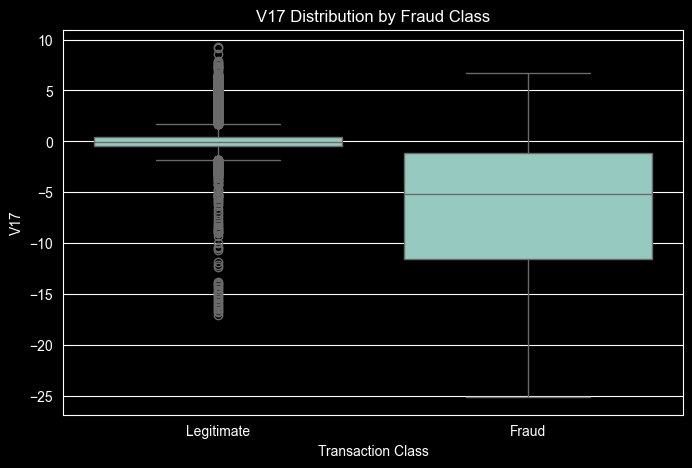

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_fraud_clean,
    x="Class",
    y="V17"
)

plt.xlabel("Transaction Class")
plt.ylabel("V17")
plt.title("V17 Distribution by Fraud Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

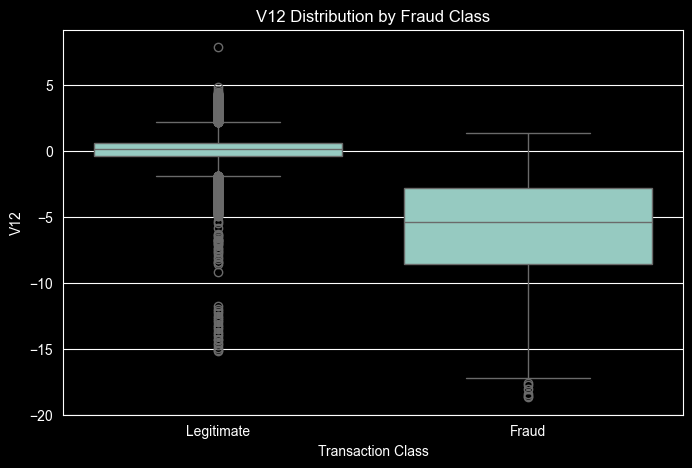

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_fraud_clean,
    x="Class",
    y="V12"
)

plt.xlabel("Transaction Class")
plt.ylabel("V12")
plt.title("V12 Distribution by Fraud Class")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [22]:
df_fraud_clean

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [23]:
X_fraud = df_fraud_clean.drop(columns=["Class"])
y_fraud = df_fraud_clean["Class"]

print("X shape:", X_fraud.shape)
print("y shape:", y_fraud.shape)

X shape: (283726, 30)
y shape: (283726,)


In [24]:
from sklearn.model_selection import train_test_split

X_train_fraud, X_test_fraud, y_train_fraud, y_test_fraud = train_test_split(
    X_fraud,
    y_fraud,
    test_size=0.20,
    random_state=42,
    stratify=y_fraud
)

print("Training set:", X_train_fraud.shape)
print("Test set:", X_test_fraud.shape)

print("\nTraining class distribution:")
print(y_train_fraud.value_counts())

print("\nTest class distribution:")
print(y_test_fraud.value_counts())

Training set: (226980, 30)
Test set: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Test class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [25]:
from sklearn.preprocessing import StandardScaler

scaler_fraud = StandardScaler()

X_train_fraud_scaled = scaler_fraud.fit_transform(X_train_fraud)
X_test_fraud_scaled = scaler_fraud.transform(X_test_fraud)

print("Scaled training shape:", X_train_fraud_scaled.shape)
print("Scaled test shape:", X_test_fraud_scaled.shape)

Scaled training shape: (226980, 30)
Scaled test shape: (56746, 30)


In [26]:
from sklearn.linear_model import LogisticRegression

fraud_logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

fraud_logistic.fit(
    X_train_fraud_scaled,
    y_train_fraud
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [27]:
y_pred_fraud_logistic = fraud_logistic.predict(X_test_fraud_scaled)

y_prob_fraud_logistic = (
    fraud_logistic.predict_proba(X_test_fraud_scaled)[:, 1]
)

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Accuracy:",
      accuracy_score(y_test_fraud, y_pred_fraud_logistic))

print("Precision:",
      precision_score(y_test_fraud, y_pred_fraud_logistic))

print("Recall:",
      recall_score(y_test_fraud, y_pred_fraud_logistic))

print("F1:",
      f1_score(y_test_fraud, y_pred_fraud_logistic))

print("ROC-AUC:",
      roc_auc_score(y_test_fraud, y_prob_fraud_logistic))

print("PR-AUC:",
      average_precision_score(
          y_test_fraud,
          y_prob_fraud_logistic
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_fraud, y_pred_fraud_logistic))

Accuracy: 0.9991188806259472
Precision: 0.8461538461538461
Recall: 0.5789473684210527
F1: 0.6875
ROC-AUC: 0.9560466717268892
PR-AUC: 0.6919665484964556

Confusion Matrix:
[[56641    10]
 [   40    55]]


In [29]:
class_weight="balanced"

In [30]:
fraud_logistic_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

fraud_logistic_balanced.fit(
    X_train_fraud_scaled,
    y_train_fraud
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [31]:
y_pred_fraud_balanced = (
    fraud_logistic_balanced.predict(X_test_fraud_scaled)
)

y_prob_fraud_balanced = (
    fraud_logistic_balanced
    .predict_proba(X_test_fraud_scaled)[:, 1]
)

In [32]:
print("Accuracy:",
      accuracy_score(y_test_fraud, y_pred_fraud_balanced))

print("Precision:",
      precision_score(y_test_fraud, y_pred_fraud_balanced))

print("Recall:",
      recall_score(y_test_fraud, y_pred_fraud_balanced))

print("F1:",
      f1_score(y_test_fraud, y_pred_fraud_balanced))

print("ROC-AUC:",
      roc_auc_score(y_test_fraud, y_prob_fraud_balanced))

print("PR-AUC:",
      average_precision_score(
          y_test_fraud,
          y_prob_fraud_balanced
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_fraud,
    y_pred_fraud_balanced
))

Accuracy: 0.9753110351390406
Precision: 0.05638586956521739
Recall: 0.8736842105263158
F1: 0.10593490746649649
ROC-AUC: 0.9656548079701293
PR-AUC: 0.6719244530518994

Confusion Matrix:
[[55262  1389]
 [   12    83]]


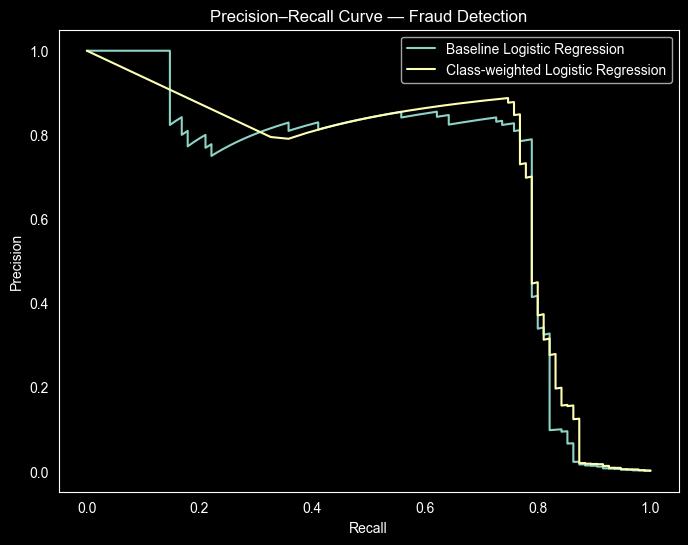

In [33]:
from sklearn.metrics import precision_recall_curve

precision_base, recall_base, thresholds_base = precision_recall_curve(
    y_test_fraud,
    y_prob_fraud_logistic
)

precision_bal, recall_bal, thresholds_bal = precision_recall_curve(
    y_test_fraud,
    y_prob_fraud_balanced
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_base,
    precision_base,
    label="Baseline Logistic Regression"
)

plt.plot(
    recall_bal,
    precision_bal,
    label="Class-weighted Logistic Regression"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Fraud Detection")
plt.legend()
plt.grid()
plt.show()

In [34]:
thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    predictions = (
        y_prob_fraud_logistic >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test_fraud,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test_fraud,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_test_fraud,
            predictions,
            zero_division=0
        ),
        "false_positives": (
            ((predictions == 1) & (y_test_fraud == 0)).sum()
        ),
        "false_negatives": (
            ((predictions == 0) & (y_test_fraud == 1)).sum()
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.05,0.808989,0.757895,0.782609,17,23
1,0.10,0.833333,0.736842,0.782123,14,25
2,0.15,0.841463,0.726316,0.779661,13,26
3,0.20,0.833333,0.684211,0.751445,13,30
4,0.25,0.826667,0.652632,0.729412,13,33
5,0.30,0.835616,0.642105,0.726190,12,34
6,0.40,0.852941,0.610526,0.711656,10,37
7,0.50,0.846154,0.578947,0.687500,10,40


In [35]:
from sklearn.ensemble import RandomForestClassifier

fraud_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

fraud_rf.fit(
    X_train_fraud,
    y_train_fraud
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [36]:
y_pred_fraud_rf = fraud_rf.predict(X_test_fraud)

y_prob_fraud_rf = fraud_rf.predict_proba(
    X_test_fraud
)[:, 1]

In [37]:
print("Accuracy:",
      accuracy_score(y_test_fraud, y_pred_fraud_rf))

print("Precision:",
      precision_score(
          y_test_fraud,
          y_pred_fraud_rf,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test_fraud,
          y_pred_fraud_rf,
          zero_division=0
      ))

print("F1:",
      f1_score(
          y_test_fraud,
          y_pred_fraud_rf,
          zero_division=0
      ))

print("ROC-AUC:",
      roc_auc_score(y_test_fraud, y_prob_fraud_rf))

print("PR-AUC:",
      average_precision_score(
          y_test_fraud,
          y_prob_fraud_rf
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_fraud,
        y_pred_fraud_rf
    )
)

Accuracy: 0.9994889507630493
Precision: 0.9714285714285714
Recall: 0.7157894736842105
F1: 0.8242424242424242
ROC-AUC: 0.9445391868402009
PR-AUC: 0.8081586358253192

Confusion Matrix:
[[56649     2]
 [   27    68]]


In [38]:
from xgboost import XGBClassifier

fraud_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

fraud_xgb.fit(
    X_train_fraud,
    y_train_fraud
)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [39]:
y_pred_fraud_xgb = fraud_xgb.predict(X_test_fraud)

y_prob_fraud_xgb = (
    fraud_xgb
    .predict_proba(X_test_fraud)[:, 1]
)

In [40]:
print("Accuracy:",
      accuracy_score(y_test_fraud, y_pred_fraud_xgb))

print("Precision:",
      precision_score(
          y_test_fraud,
          y_pred_fraud_xgb,
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test_fraud,
          y_pred_fraud_xgb,
          zero_division=0
      ))

print("F1:",
      f1_score(
          y_test_fraud,
          y_pred_fraud_xgb,
          zero_division=0
      ))

print("ROC-AUC:",
      roc_auc_score(
          y_test_fraud,
          y_prob_fraud_xgb
      ))

print("PR-AUC:",
      average_precision_score(
          y_test_fraud,
          y_prob_fraud_xgb
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_fraud,
        y_pred_fraud_xgb
    )
)

Accuracy: 0.9995241955380115
Precision: 0.9594594594594594
Recall: 0.7473684210526316
F1: 0.8402366863905325
ROC-AUC: 0.9783970924469211
PR-AUC: 0.8386053419694725

Confusion Matrix:
[[56648     3]
 [   24    71]]


In [41]:
fraud_model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test_fraud, y_pred_fraud_logistic),
        accuracy_score(y_test_fraud, y_pred_fraud_balanced),
        accuracy_score(y_test_fraud, y_pred_fraud_rf),
        accuracy_score(y_test_fraud, y_pred_fraud_xgb)
    ],
    "Precision": [
        precision_score(y_test_fraud, y_pred_fraud_logistic),
        precision_score(y_test_fraud, y_pred_fraud_balanced),
        precision_score(y_test_fraud, y_pred_fraud_rf),
        precision_score(y_test_fraud, y_pred_fraud_xgb)
    ],
    "Recall": [
        recall_score(y_test_fraud, y_pred_fraud_logistic),
        recall_score(y_test_fraud, y_pred_fraud_balanced),
        recall_score(y_test_fraud, y_pred_fraud_rf),
        recall_score(y_test_fraud, y_pred_fraud_xgb)
    ],
    "F1": [
        f1_score(y_test_fraud, y_pred_fraud_logistic),
        f1_score(y_test_fraud, y_pred_fraud_balanced),
        f1_score(y_test_fraud, y_pred_fraud_rf),
        f1_score(y_test_fraud, y_pred_fraud_xgb)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test_fraud, y_prob_fraud_logistic),
        roc_auc_score(y_test_fraud, y_prob_fraud_balanced),
        roc_auc_score(y_test_fraud, y_prob_fraud_rf),
        roc_auc_score(y_test_fraud, y_prob_fraud_xgb)
    ],
    "PR_AUC": [
        average_precision_score(y_test_fraud, y_prob_fraud_logistic),
        average_precision_score(y_test_fraud, y_prob_fraud_balanced),
        average_precision_score(y_test_fraud, y_prob_fraud_rf),
        average_precision_score(y_test_fraud, y_prob_fraud_xgb)
    ]
})

fraud_model_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.9991,0.8462,0.5789,0.6875,0.9560,0.6920
1,Balanced Logistic Regression,0.9753,0.0564,0.8737,0.1059,0.9657,0.6719
2,Random Forest,0.9995,0.9714,0.7158,0.8242,0.9445,0.8082
3,XGBoost,0.9995,0.9595,0.7474,0.8402,0.9784,0.8386


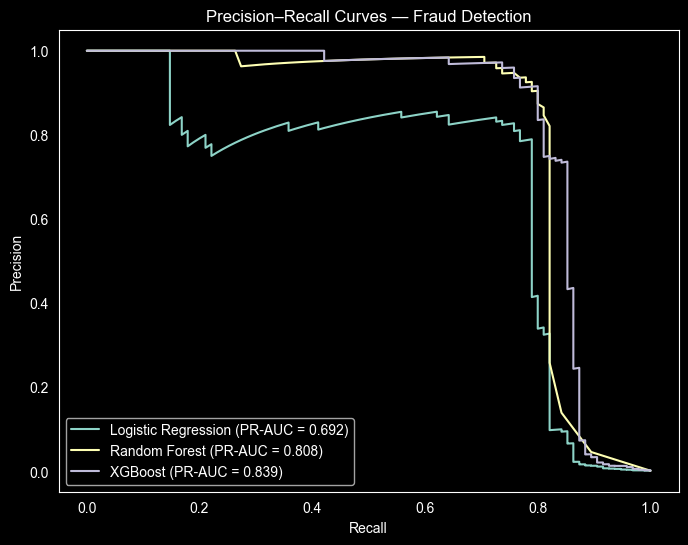

In [42]:
precision_lr, recall_lr, _ = precision_recall_curve(
    y_test_fraud,
    y_prob_fraud_logistic
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test_fraud,
    y_prob_fraud_rf
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test_fraud,
    y_prob_fraud_xgb
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lr,
    precision_lr,
    label="Logistic Regression (PR-AUC = 0.692)"
)

plt.plot(
    recall_rf,
    precision_rf,
    label="Random Forest (PR-AUC = 0.808)"
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label="XGBoost (PR-AUC = 0.839)"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Fraud Detection")
plt.legend()
plt.grid()
plt.show()

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_validate

fraud_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [44]:
fraud_xgb_cv = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=4
)

In [45]:
xgb_cv_results = cross_validate(
    fraud_xgb_cv,
    X_train_fraud,
    y_train_fraud,
    cv=fraud_cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "average_precision"
    ],
    n_jobs=1
)

In [46]:
xgb_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Mean": [
        xgb_cv_results["test_accuracy"].mean(),
        xgb_cv_results["test_precision"].mean(),
        xgb_cv_results["test_recall"].mean(),
        xgb_cv_results["test_f1"].mean(),
        xgb_cv_results["test_roc_auc"].mean(),
        xgb_cv_results["test_average_precision"].mean()
    ],
    "Std": [
        xgb_cv_results["test_accuracy"].std(),
        xgb_cv_results["test_precision"].std(),
        xgb_cv_results["test_recall"].std(),
        xgb_cv_results["test_f1"].std(),
        xgb_cv_results["test_roc_auc"].std(),
        xgb_cv_results["test_average_precision"].std()
    ]
})

xgb_cv_summary.round(4)

,Metric,Mean,Std
0,Accuracy,0.9996,0.0000
1,Precision,0.9443,0.0229
2,Recall,0.7804,0.0431
3,F1,0.8533,0.0161
4,ROC-AUC,0.9835,0.0047
5,PR-AUC,0.8511,0.0201


In [47]:
from sklearn.model_selection import cross_val_predict

xgb_oof_prob = cross_val_predict(
    fraud_xgb_cv,
    X_train_fraud,
    y_train_fraud,
    cv=fraud_cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

In [48]:
thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90
]

threshold_results_xgb = []

for threshold in thresholds:

    predictions = (
        xgb_oof_prob >= threshold
    ).astype(int)

    threshold_results_xgb.append({
        "threshold": threshold,
        "precision": precision_score(
            y_train_fraud,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_train_fraud,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_train_fraud,
            predictions,
            zero_division=0
        ),
        "false_positives": (
            ((predictions == 1) & (y_train_fraud == 0)).sum()
        ),
        "false_negatives": (
            ((predictions == 0) & (y_train_fraud == 1)).sum()
        )
    })

threshold_results_xgb_df = pd.DataFrame(
    threshold_results_xgb
)

threshold_results_xgb_df.round(4)

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.05,0.7854,0.8519,0.8173,88,56
1,0.10,0.8729,0.8360,0.8541,46,62
2,0.15,0.8914,0.8254,0.8571,38,66
3,0.20,0.9032,0.8148,0.8567,33,70
4,0.25,0.9080,0.8095,0.8559,31,72
5,0.30,0.9157,0.8042,0.8563,28,74
6,0.40,0.9319,0.7963,0.8588,22,77
7,0.50,0.9425,0.7804,0.8538,18,83
8,0.60,0.9507,0.7646,0.8475,15,89
9,0.70,0.9593,0.7487,0.8410,12,95


In [49]:
final_fraud_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

final_fraud_xgb.fit(
    X_train_fraud,
    y_train_fraud
)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [50]:
final_fraud_prob = final_fraud_xgb.predict_proba(
    X_test_fraud
)[:, 1]

In [51]:
selected_threshold = 0.20

final_fraud_pred = (
    final_fraud_prob >= selected_threshold
).astype(int)

In [52]:
final_accuracy = accuracy_score(
    y_test_fraud,
    final_fraud_pred
)

final_precision = precision_score(
    y_test_fraud,
    final_fraud_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test_fraud,
    final_fraud_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test_fraud,
    final_fraud_pred,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test_fraud,
    final_fraud_prob
)

final_pr_auc = average_precision_score(
    y_test_fraud,
    final_fraud_prob
)

final_cm = confusion_matrix(
    y_test_fraud,
    final_fraud_pred
)

print("Threshold:", selected_threshold)
print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1:", final_f1)
print("ROC-AUC:", final_roc_auc)
print("PR-AUC:", final_pr_auc)

print("\nConfusion Matrix:")
print(final_cm)

Threshold: 0.2
Accuracy: 0.9995065731505305
Precision: 0.9240506329113924
Recall: 0.7684210526315789
F1: 0.8390804597701149
ROC-AUC: 0.9783970924469211
PR-AUC: 0.8386053419694725

Confusion Matrix:
[[56645     6]
 [   22    73]]


In [53]:
import shap
import numpy as np

X_test_fraud_shap = X_test_fraud.sample(
    n=min(1000, len(X_test_fraud)),
    random_state=42
)

print("SHAP sample shape:", X_test_fraud_shap.shape)

SHAP sample shape: (1000, 30)


In [54]:
fraud_explainer = shap.TreeExplainer(
    final_fraud_xgb
)

fraud_shap_values = fraud_explainer.shap_values(
    X_test_fraud_shap
)

print("SHAP values shape:", fraud_shap_values.shape)

SHAP values shape: (1000, 30)


In [55]:
fraud_shap_importance = pd.DataFrame({
    "feature": X_test_fraud_shap.columns,
    "mean_abs_shap": np.abs(
        fraud_shap_values
    ).mean(axis=0)
})

fraud_shap_importance = (
    fraud_shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

fraud_shap_importance

,feature,mean_abs_shap
0,V4,1.189428
1,V10,0.780946
2,V14,0.773861
3,V12,0.767561
4,V11,0.327344
5,V8,0.251555
6,V19,0.233141
7,V3,0.218077
8,Amount,0.204787
9,Time,0.198882


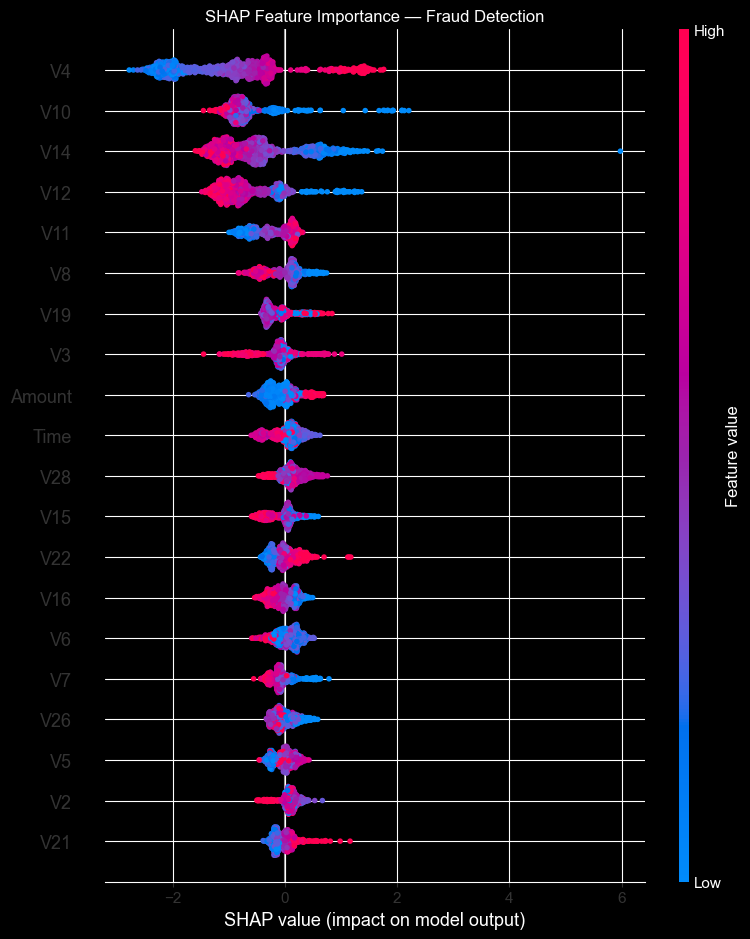

In [56]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    fraud_shap_values,
    X_test_fraud_shap,
    show=False
)

plt.title(
    "SHAP Feature Importance — Fraud Detection"
)

plt.tight_layout()
plt.show()

In [57]:
fraud_cases = pd.DataFrame({
    "actual": y_test_fraud.values,
    "predicted": final_fraud_pred,
    "fraud_probability": final_fraud_prob
}, index=X_test_fraud.index)

correct_fraud_cases = fraud_cases[
    (fraud_cases["actual"] == 1) &
    (fraud_cases["predicted"] == 1)
].sort_values(
    "fraud_probability",
    ascending=False
)

correct_fraud_cases.head(10)

,actual,predicted,fraud_probability
42769,1,1,0.998750
153835,1,1,0.998705
42009,1,1,0.998643
43160,1,1,0.998421
151807,1,1,0.997620
151011,1,1,0.995994
143188,1,1,0.995097
18773,1,1,0.994882
223618,1,1,0.994793
149874,1,1,0.994735


In [58]:
selected_index = correct_fraud_cases.index[0]

selected_transaction = X_test_fraud.loc[
    selected_index
]

selected_probability = final_fraud_prob[
    list(X_test_fraud.index).index(selected_index)
]

print("Transaction index:", selected_index)
print("Actual class:", y_test_fraud.loc[selected_index])
print("Predicted class:", final_fraud_pred[
    list(X_test_fraud.index).index(selected_index)
])
print("Fraud probability:", selected_probability)

selected_transaction

Transaction index: 42769
Actual class: 1
Predicted class: 1
Fraud probability: 0.99874985


Time      41237.000000
V1          -10.281784
V2            6.302385
V3          -13.271718
V4            8.925115
V5           -9.975578
V6           -2.832513
V7          -12.703253
V8            6.706846
V9           -7.078424
V10         -12.805683
V11           6.786058
V12         -13.064240
V13           1.179525
V14         -13.694873
V15           0.951479
V16         -10.954286
V17         -20.583593
V18          -7.517262
V19           2.872354
V20          -0.247648
V21           2.479414
V22           0.366933
V23           0.042805
V24           0.478279
V25           0.157771
V26           0.329901
V27           0.163504
V28          -0.485552
Amount      118.300000
Name: 42769, dtype: float64

In [59]:
selected_index = correct_fraud_cases.index[0]

selected_transaction = X_test_fraud.loc[
    selected_index
]

selected_probability = final_fraud_prob[
    list(X_test_fraud.index).index(selected_index)
]

print("Transaction index:", selected_index)
print("Actual class:", y_test_fraud.loc[selected_index])
print("Predicted class:", final_fraud_pred[
    list(X_test_fraud.index).index(selected_index)
])
print("Fraud probability:", selected_probability)

selected_transaction

Transaction index: 42769
Actual class: 1
Predicted class: 1
Fraud probability: 0.99874985


Time      41237.000000
V1          -10.281784
V2            6.302385
V3          -13.271718
V4            8.925115
V5           -9.975578
V6           -2.832513
V7          -12.703253
V8            6.706846
V9           -7.078424
V10         -12.805683
V11           6.786058
V12         -13.064240
V13           1.179525
V14         -13.694873
V15           0.951479
V16         -10.954286
V17         -20.583593
V18          -7.517262
V19           2.872354
V20          -0.247648
V21           2.479414
V22           0.366933
V23           0.042805
V24           0.478279
V25           0.157771
V26           0.329901
V27           0.163504
V28          -0.485552
Amount      118.300000
Name: 42769, dtype: float64

In [60]:
local_shap_values = fraud_explainer.shap_values(
    selected_transaction.to_frame().T
)

print("Local SHAP shape:", local_shap_values.shape)

Local SHAP shape: (1, 30)


In [61]:
local_shap_df = pd.DataFrame({
    "feature": X_test_fraud.columns,
    "feature_value": selected_transaction.values,
    "shap_value": local_shap_values[0]
})

local_shap_df["absolute_shap"] = (
    local_shap_df["shap_value"].abs()
)

local_shap_df = (
    local_shap_df
    .sort_values(
        "absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

local_shap_df.head(15)

,feature,feature_value,shap_value,absolute_shap
0,V14,-13.694873,6.055239,6.055239
1,V10,-12.805683,1.669791,1.669791
2,V12,-13.064240,1.416542,1.416542
3,V4,8.925115,1.148275,1.148275
4,V21,2.479414,0.688958,0.688958
5,Amount,118.300000,0.651798,0.651798
6,V7,-12.703253,0.634615,0.634615
7,V16,-10.954286,0.398991,0.398991
8,V28,-0.485552,0.276625,0.276625
9,V11,6.786058,0.249765,0.249765


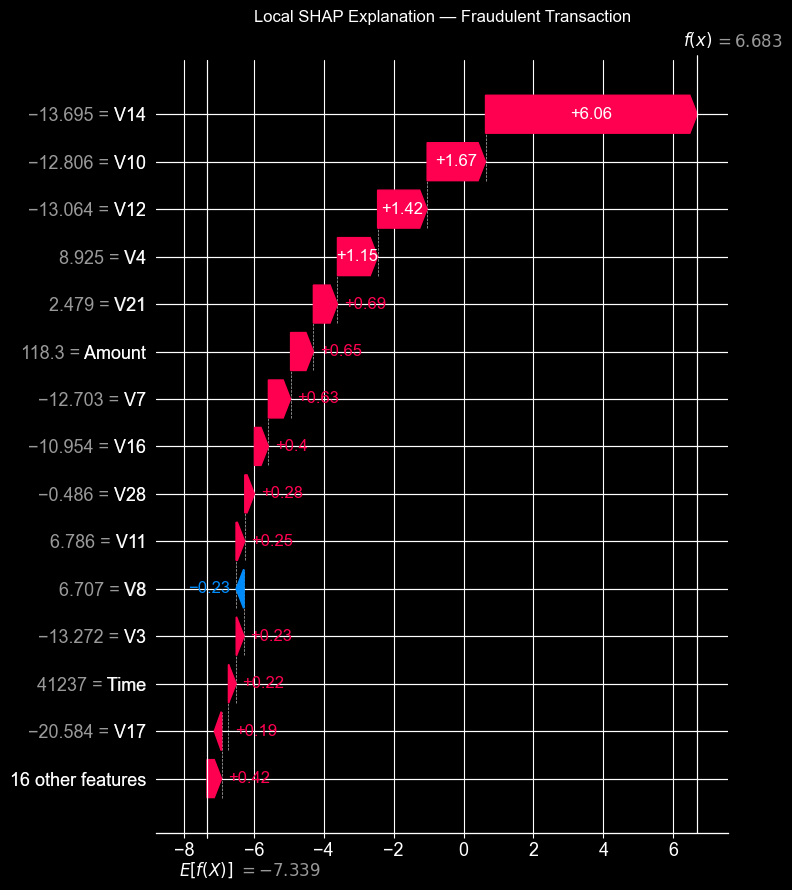

In [62]:
local_explanation = shap.Explanation(
    values=local_shap_values[0],
    base_values=fraud_explainer.expected_value,
    data=selected_transaction.values,
    feature_names=X_test_fraud.columns
)

shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=False
)

plt.title(
    "Local SHAP Explanation — Fraudulent Transaction"
)

plt.tight_layout()
plt.show()

In [63]:
print("Transaction index:", selected_index)
print("Actual class:", y_test_fraud.loc[selected_index])

selected_position = X_test_fraud.index.get_loc(
    selected_index
)

print(
    "Fraud probability:",
    final_fraud_prob[selected_position]
)

print(
    "Predicted class:",
    final_fraud_pred[selected_position]
)

Transaction index: 42769
Actual class: 1
Fraud probability: 0.99874985
Predicted class: 1


In [64]:
from src.monitoring.data_quality import check_data_quality

fraud_quality = check_data_quality(
    df_fraud_clean
)

fraud_quality

{'missing_values': 0, 'duplicate_rows': 0, 'infinite_values': 0}

In [65]:
fraud_feature_columns = [
    "Time",
    "V1", "V2", "V3", "V4", "V5",
    "V6", "V7", "V8", "V9", "V10",
    "V11", "V12", "V13", "V14", "V15",
    "V16", "V17", "V18", "V19", "V20",
    "V21", "V22", "V23", "V24", "V25",
    "V26", "V27", "V28",
    "Amount"
]

In [66]:
fraud_quality = check_data_quality(
    df_fraud_clean,
    expected_columns=fraud_feature_columns + ["Class"]
)

fraud_quality

{'missing_values': 0,
 'duplicate_rows': 0,
 'infinite_values': 0,
 'missing_columns': [],
 'unexpected_columns': []}

In [67]:
from src.monitoring.model_monitoring import prediction_monitoring
monitoring_report = prediction_monitoring(
    probabilities=final_fraud_prob,
    predictions=final_fraud_pred,
    threshold=0.20
)

monitoring_report

number_of_predictions        5.674600e+04
average_fraud_probability    1.442890e-03
maximum_fraud_probability    9.987499e-01
minimum_fraud_probability    2.239487e-07
flagged_transactions         7.900000e+01
flagged_rate                 1.392169e-03
threshold                    2.000000e-01
dtype: float64

In [68]:
from src.monitoring.model_monitoring import risk_band_distribution

In [69]:
risk_bands = risk_band_distribution(
    final_fraud_prob
)

risk_bands

Low         56651
Medium         16
High            5
Critical       74
Name: count, dtype: int64

In [70]:
fraud_monitoring_features = [
    "Time",
    "Amount",
    "V4",
    "V10",
    "V12",
    "V14"
]

fraud_monitoring_features

['Time', 'Amount', 'V4', 'V10', 'V12', 'V14']

In [71]:
from src.monitoring.model_monitoring import calculate_feature_drift

drift_report = calculate_feature_drift(
    reference_df=X_train_fraud,
    current_df=X_test_fraud,
    features=fraud_monitoring_features
)

drift_report

,feature,reference_mean,current_mean,mean_shift_std
0,Time,94900.224390,94454.496722,-0.009386
1,Amount,88.387124,88.814933,0.001741
2,V4,-0.002025,-0.006730,-0.003320
3,V10,-0.002180,0.001515,0.003443
4,V12,0.000046,-0.003760,-0.003835
5,V14,-0.001629,0.007779,0.009859


In [72]:
drift_report["drift_flag"] = (
    drift_report["mean_shift_std"].abs() >= 1
)

drift_report

,feature,reference_mean,current_mean,mean_shift_std,drift_flag
0,Time,94900.224390,94454.496722,-0.009386,False
1,Amount,88.387124,88.814933,0.001741,False
2,V4,-0.002025,-0.006730,-0.003320,False
3,V10,-0.002180,0.001515,0.003443,False
4,V12,0.000046,-0.003760,-0.003835,False
5,V14,-0.001629,0.007779,0.009859,False


In [73]:
from src.monitoring.drift_monitoring import calculate_ks_drift

ks_drift_report = calculate_ks_drift(
    reference_df=X_train_fraud,
    current_df=X_test_fraud,
    features=fraud_monitoring_features
)

ks_drift_report

,feature,ks_statistic,p_value
0,Time,0.006008,0.075145
1,Amount,0.005328,0.151313
2,V4,0.002845,0.854930
3,V10,0.002519,0.934853
4,V12,0.004650,0.279085
5,V14,0.006365,0.050307


In [74]:
ks_drift_report["drift_flag"] = ks_drift_report["ks_statistic"] >= 0.10

ks_drift_report

,feature,ks_statistic,p_value,drift_flag
0,Time,0.006008,0.075145,False
1,Amount,0.005328,0.151313,False
2,V4,0.002845,0.854930,False
3,V10,0.002519,0.934853,False
4,V12,0.004650,0.279085,False
5,V14,0.006365,0.050307,False


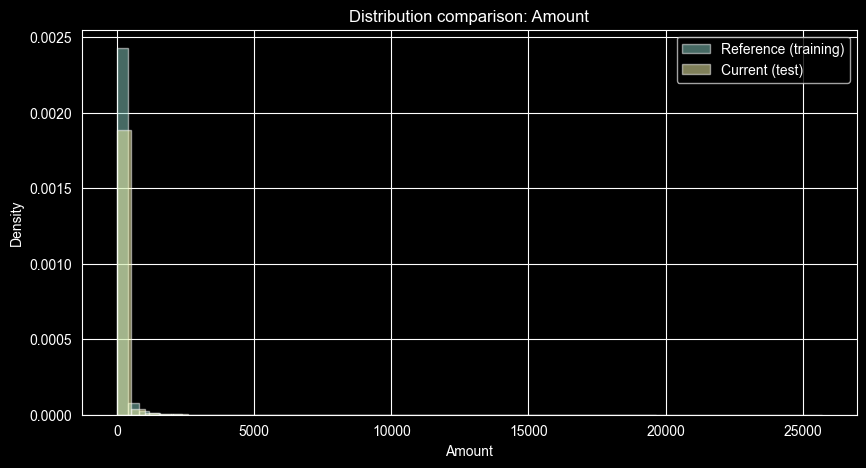

In [75]:
import matplotlib.pyplot as plt

feature = "Amount"

plt.figure(figsize=(10, 5))

plt.hist(
    X_train_fraud[feature],
    bins=50,
    alpha=0.5,
    density=True,
    label="Reference (training)"
)

plt.hist(
    X_test_fraud[feature],
    bins=50,
    alpha=0.5,
    density=True,
    label="Current (test)"
)

plt.xlabel(feature)
plt.ylabel("Density")
plt.title(f"Distribution comparison: {feature}")
plt.legend()
plt.show()

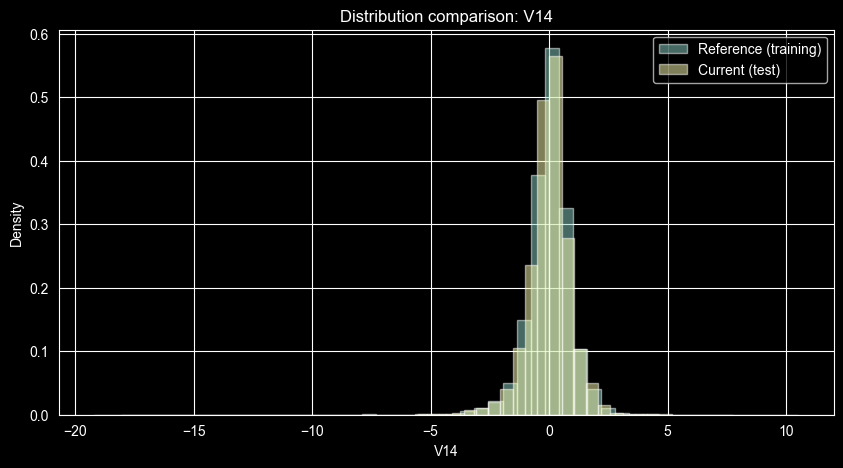

In [76]:
feature = "V14"

plt.figure(figsize=(10, 5))

plt.hist(
    X_train_fraud[feature],
    bins=50,
    alpha=0.5,
    density=True,
    label="Reference (training)"
)

plt.hist(
    X_test_fraud[feature],
    bins=50,
    alpha=0.5,
    density=True,
    label="Current (test)"
)

plt.xlabel(feature)
plt.ylabel("Density")
plt.title(f"Distribution comparison: {feature}")
plt.legend()
plt.show()

In [92]:
from pathlib import Path
import joblib

# Point directly to your project's models folder
MODEL_DIR = Path(
    "Desktop/Banking_AI_Risk_Engine/models"
)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted scaler that you verified
joblib.dump(
    loaded_scaler,
    MODEL_DIR / "scaler_fraud.joblib"
)

print("Scaler saved to:", MODEL_DIR / "scaler_fraud.joblib")
print("File exists:", (MODEL_DIR / "scaler_fraud.joblib").exists())

Scaler saved to: Desktop/Banking_AI_Risk_Engine/models/scaler_fraud.joblib
File exists: True


In [79]:
import joblib

# Save the fitted model directly
joblib.dump(
    final_fraud_xgb,
    "../models/fraud_xgb_model.joblib"
)

# Reload the saved model
loaded_model = joblib.load(
    "../models/fraud_xgb_model.joblib"
)

# Verify the reloaded model
print(loaded_model.get_booster())

In [83]:

loaded_scaler = joblib.load(
    "../models/scaler_fraud.joblib"
)

loaded_threshold = joblib.load(
    "../models/fraud_threshold.joblib"
)

print("Model, scaler, and threshold loaded successfully.")
print("Fraud threshold:", loaded_threshold)

Model, scaler, and threshold loaded successfully.
Fraud threshold: 0.2


In [84]:
# Select one original, unscaled test transaction
sample_transaction = X_test_fraud.iloc[[0]]

# Scale it using the saved scaler
sample_scaled = loaded_scaler.transform(sample_transaction)

# Predict fraud probability
sample_probability = loaded_model.predict_proba(
    sample_scaled
)[:, 1][0]

# Apply the saved threshold
prediction = int(sample_probability >= loaded_threshold)

print(f"Fraud probability: {sample_probability:.4%}")
print(f"Decision threshold: {loaded_threshold:.0%}")
print(
    "Prediction:",
    "FRAUD — FLAG FOR REVIEW" if prediction == 1
    else "LEGITIMATE — NOT FLAGGED"
)

Fraud probability: 0.0021%
Decision threshold: 20%
Prediction: LEGITIMATE — NOT FLAGGED


In [85]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Transform the complete test dataset
X_test_scaled = loaded_scaler.transform(X_test_fraud)

# Calculate fraud probabilities
fraud_probabilities = loaded_model.predict_proba(
    X_test_scaled
)[:, 1]

# Apply the saved 0.20 threshold
fraud_predictions = (
    fraud_probabilities >= loaded_threshold
).astype(int)

# Evaluate the reloaded model
print("Precision:", round(
    precision_score(y_test_fraud, fraud_predictions), 4
))
print("Recall:", round(
    recall_score(y_test_fraud, fraud_predictions), 4
))
print("F1-score:", round(
    f1_score(y_test_fraud, fraud_predictions), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_fraud, fraud_probabilities), 4
))
print("PR-AUC:", round(
    average_precision_score(y_test_fraud, fraud_probabilities), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_fraud, fraud_predictions))


Precision: 0.7912
Recall: 0.7579
F1-score: 0.7742
ROC-AUC: 0.956
PR-AUC: 0.7863

Confusion matrix:
[[56632    19]
 [   23    72]]


In [86]:

import numpy as np

# Transform the test data once
X_test_scaled = loaded_scaler.transform(X_test_fraud)

# Predictions from the reloaded model
loaded_probabilities = loaded_model.predict_proba(
    X_test_scaled
)[:, 1]

# Predictions from the original fitted model
original_probabilities = final_fraud_xgb.predict_proba(
    X_test_scaled
)[:, 1]

print(
    "Predictions match:",
    np.allclose(
        loaded_probabilities,
        original_probabilities,
        rtol=1e-5,
        atol=1e-7
    )
)

print(
    "Maximum probability difference:",
    np.max(np.abs(
        loaded_probabilities - original_probabilities
    ))
)


Predictions match: True
Maximum probability difference: 0.0


In [87]:

print("Test feature shape:", X_test_fraud.shape)
print("Test target shape:", y_test_fraud.shape)

print("\nTest target distribution:")
print(y_test_fraud.value_counts().sort_index())

print("\nFraud scaler details:")
print("Scaler type:", type(loaded_scaler).__name__)

print("\nFeature count expected by model:")
print(loaded_model.n_features_in_)

print("\nFeature count supplied to model:")
print(X_test_scaled.shape[1])

print("\nThreshold:", loaded_threshold)


Test feature shape: (56746, 30)
Test target shape: (56746,)

Test target distribution:
Class
0    56651
1       95
Name: count, dtype: int64

Fraud scaler details:
Scaler type: StandardScaler

Feature count expected by model:
30

Feature count supplied to model:
30

Threshold: 0.2


In [88]:

import numpy as np

print(
    "Scaler means match:",
    np.allclose(loaded_scaler.mean_, scaler_fraud.mean_)
)

print(
    "Scaler standard deviations match:",
    np.allclose(loaded_scaler.scale_, scaler_fraud.scale_)
)


Scaler means match: True
Scaler standard deviations match: True


In [89]:

print("Loaded model parameters:")
print(loaded_model.get_params())

print("\nOriginal model parameters:")
print(final_fraud_xgb.get_params())

print("\nLoaded model booster trees:")
print(loaded_model.get_booster().num_boosted_rounds())

print("\nOriginal model booster trees:")
print(final_fraud_xgb.get_booster().num_boosted_rounds())


Loaded model parameters:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 4, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 300, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}

Original model parameters:
{'objective': 'binary:logist

In [90]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import numpy as np

# Recalculate probabilities from the verified model
X_test_scaled = loaded_scaler.transform(X_test_fraud)

probabilities = loaded_model.predict_proba(
    X_test_scaled
)[:, 1]

# Apply the saved threshold
predictions = (probabilities >= loaded_threshold).astype(int)

print("Threshold:", loaded_threshold)
print("Predicted fraud cases:", int(predictions.sum()))
print("Actual fraud cases:", int(y_test_fraud.sum()))
print("Precision:", round(precision_score(y_test_fraud, predictions), 4))
print("Recall:", round(recall_score(y_test_fraud, predictions), 4))
print("F1-score:", round(f1_score(y_test_fraud, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_fraud, probabilities), 4))
print("PR-AUC:", round(average_precision_score(y_test_fraud, probabilities), 4))
print("Confusion matrix:\n", confusion_matrix(y_test_fraud, predictions))


Threshold: 0.2
Predicted fraud cases: 91
Actual fraud cases: 95
Precision: 0.7912
Recall: 0.7579
F1-score: 0.7742
ROC-AUC: 0.956
PR-AUC: 0.7863
Confusion matrix:
 [[56632    19]
 [   23    72]]


In [93]:

print("Number of features:", X_train_fraud.shape[1])
print("\nFeature names and order:")

for position, feature in enumerate(X_train_fraud.columns, start=1):
    print(f"{position:02d}. {feature}")


Number of features: 30

Feature names and order:
01. Time
02. V1
03. V2
04. V3
05. V4
06. V5
07. V6
08. V7
09. V8
10. V9
11. V10
12. V11
13. V12
14. V13
15. V14
16. V15
17. V16
18. V17
19. V18
20. V19
21. V20
22. V21
23. V22
24. V23
25. V24
26. V25
27. V26
28. V27
29. V28
30. Amount


In [94]:

import joblib
from pathlib import Path

project_root = Path(
    "/Users/sugunaramachandran/Desktop/Banking_AI_Risk_Engine"
)

feature_names = list(X_train_fraud.columns)

joblib.dump(
    feature_names,
    project_root / "models" / "fraud_feature_names.joblib"
)

print("Saved feature names:", len(feature_names))
print("Feature order saved successfully.")


Saved feature names: 30
Feature order saved successfully.
